In [3]:
print("My OpenPIV Wake Analysis project has started!")

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Matplotlib is ready!")

My OpenPIV Wake Analysis project has started!
NumPy version: 2.1.3
Matplotlib is ready!


In [4]:
%pip install openpiv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 MB 14.1 MB/s eta 0:00:00


In [5]:
import openpiv

print("OpenPIV imported successfully!")
print("Installed version: 0.26.1")
print("Library location:", openpiv.__file__)

OpenPIV imported successfully!
Installed version: 0.26.1
Library location: /usr/local/lib/python3.13/dist-packages/openpiv/__init__.py


In [6]:
import requests

repo_url = "https://api.github.com/repos/Karthik2312062/openpiv-wake-analysis"
response = requests.get(repo_url)

print("GitHub response:", response.status_code)

if response.status_code == 200:
    repo = response.json()
    print("Repository:", repo["full_name"])
    print("Default branch:", repo["default_branch"])
else:
    print("Check your GitHub username and repository name.")

GitHub response: 200
Repository: Karthik2312062/openpiv-wake-analysis
Default branch: main


In [7]:
import requests
import zipfile
import io
import os

repo_zip = "https://github.com/OpenPIV/openpiv-python-examples/archive/refs/heads/main.zip"

response = requests.get(repo_zip, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/")

print("OpenPIV example repository downloaded successfully!")
print("Files extracted to /content/")

OpenPIV example repository downloaded successfully!
Files extracted to /content/


In [8]:
import os

data_root = "/content/openpiv-python-examples-main"

image_extensions = (".tif", ".tiff", ".bmp", ".png", ".jpg", ".jpeg")

image_files = []

for root, dirs, files in os.walk(data_root):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total image files found:", len(image_files))

for path in image_files[:40]:
    print(path)

Total image files found: 160
/content/openpiv-python-examples-main/test21/bubblesMask.png
/content/openpiv-python-examples-main/test21/bubblesFrameA.png
/content/openpiv-python-examples-main/test21/bubblesFrameB.png
/content/openpiv-python-examples-main/two_phase_piv/real_A.tif
/content/openpiv-python-examples-main/two_phase_piv/real_B.tif
/content/openpiv-python-examples-main/two_phase_piv/artificial_A.tif
/content/openpiv-python-examples-main/test7/E001_1.tif
/content/openpiv-python-examples-main/test7/E001_2.tif
/content/openpiv-python-examples-main/test9/karman_16Hz_000_A.jpg
/content/openpiv-python-examples-main/test9/karman_16Hz_000_B.jpg
/content/openpiv-python-examples-main/output_3D_test/displaced_bar_deformation_field.png
/content/openpiv-python-examples-main/output_3D_test/displaced_bar_frame1.png
/content/openpiv-python-examples-main/output_3D_test/displaced_bar_frame2.png
/content/openpiv-python-examples-main/output_3D_test/displaced_bar_sig2noise.png
/content/openpiv-pyth

karman_16Hz_000_A.jpg — image size: (1024, 512)
karman_16Hz_000_B.jpg — image size: (1024, 512)


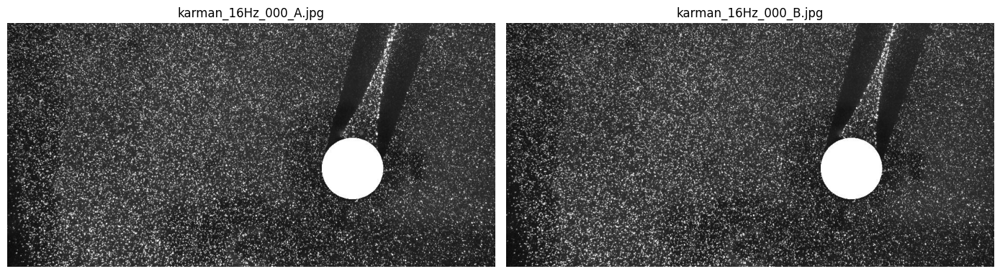

In [9]:
from PIL import Image
import matplotlib.pyplot as plt
import os

data_dir = "/content/openpiv-python-examples-main/test9"

image_a = os.path.join(data_dir, "karman_16Hz_000_A.jpg")
image_b = os.path.join(data_dir, "karman_16Hz_000_B.jpg")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, path in zip(axes, [image_a, image_b]):
    img = Image.open(path)
    ax.imshow(img, cmap="gray")
    ax.set_title(os.path.basename(path))
    ax.axis("off")
    print(os.path.basename(path), "— image size:", img.size)

plt.tight_layout()
plt.show()

Velocity-field grid: (31, 63)
Mean horizontal displacement: -1.9547229200236018 pixels
Mean vertical displacement: 0.04391849602309729 pixels


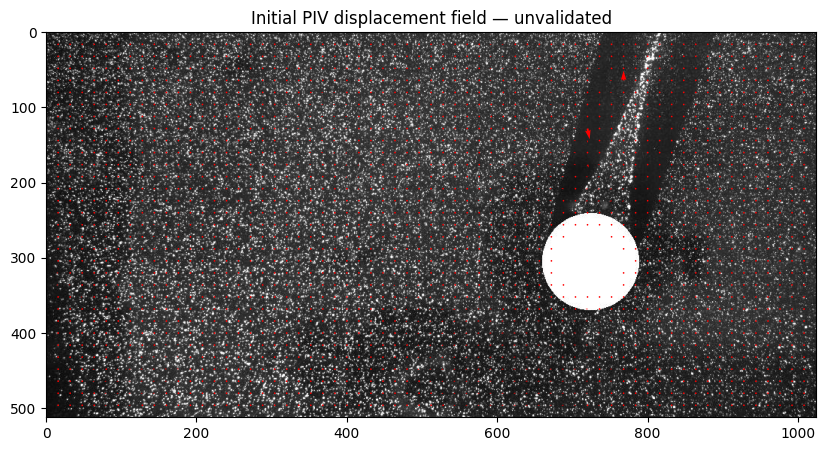

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from openpiv import pyprocess, validation, filters
from PIL import Image
import os

data_dir = "/content/openpiv-python-examples-main/test9"

frame_a = np.array(
    Image.open(os.path.join(data_dir, "karman_16Hz_000_A.jpg")).convert("L")
)
frame_b = np.array(
    Image.open(os.path.join(data_dir, "karman_16Hz_000_B.jpg")).convert("L")
)

# Initial PIV settings (pixels)
window_size = 32
overlap = 16
search_area_size = 32

u, v, signal_to_noise = pyprocess.extended_search_area_piv(
    frame_a.astype(np.int32),
    frame_b.astype(np.int32),
    window_size=window_size,
    overlap=overlap,
    dt=1.0,  # Placeholder: displacement output is in pixels per arbitrary time unit
    search_area_size=search_area_size,
    sig2noise_method="peak2peak"
)

x, y = pyprocess.get_coordinates(
    image_size=frame_a.shape,
    search_area_size=window_size,
    overlap=overlap
)

print("Velocity-field grid:", u.shape)
print("Mean horizontal displacement:", np.nanmean(u), "pixels")
print("Mean vertical displacement:", np.nanmean(v), "pixels")

plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")
plt.quiver(x, y, u, -v, color="red", angles="xy", scale_units="xy", scale=1)
plt.title("Initial PIV displacement field — unvalidated")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.show()

Total vectors: 1953
Flagged as invalid: 1547
Invalid fraction: 79.21 %


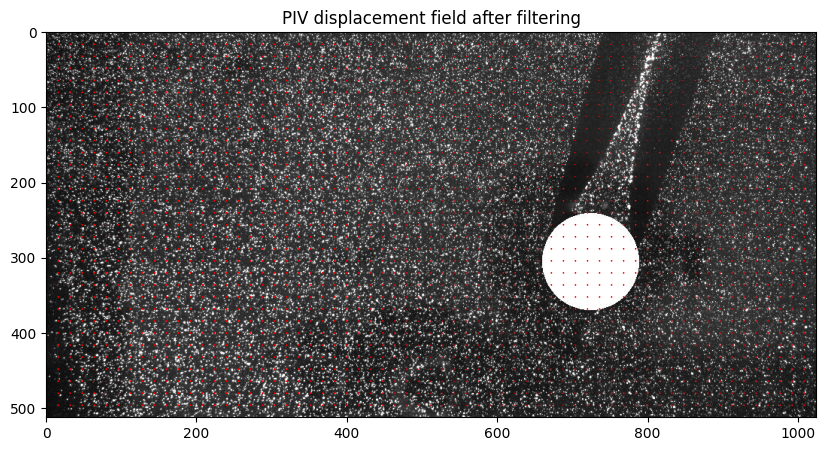

In [11]:
from openpiv import validation, filters
import numpy as np
import matplotlib.pyplot as plt

# Flag vectors with a low signal-to-noise ratio
invalid = validation.sig2noise_val(
    signal_to_noise, threshold=1.3
)

print("Total vectors:", invalid.size)
print("Flagged as invalid:", np.count_nonzero(invalid))
print("Invalid fraction:", round(100 * np.mean(invalid), 2), "%")

# Replace flagged vectors using neighbouring values
u_clean, v_clean = filters.replace_outliers(
    u, v, invalid,
    method="localmean",
    max_iter=5,
    kernel_size=3
)

# Plot the filtered displacement field
plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")
plt.quiver(
    x, y, u_clean, -v_clean,
    color="red", angles="xy",
    scale_units="xy", scale=1
)
plt.title("PIV displacement field after filtering")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.show()

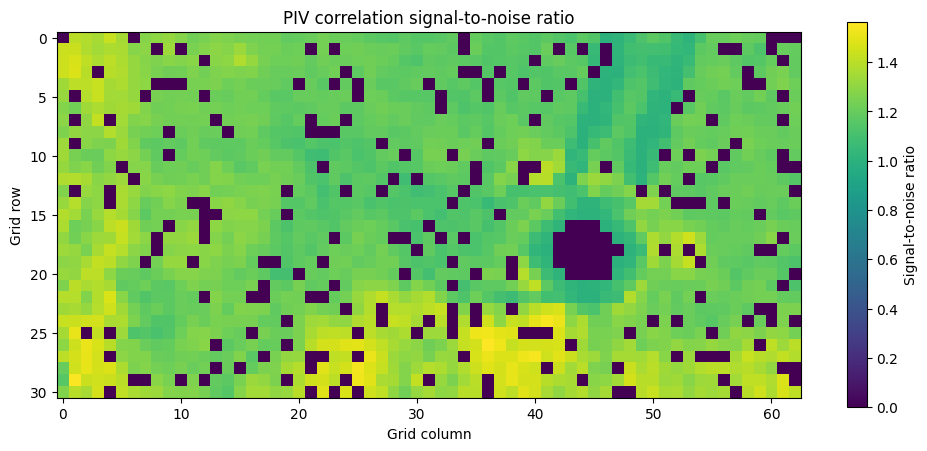

Minimum SNR: 0.0
Median SNR: 1.2041461527504966
Maximum SNR: 1.5618024364949905


In [12]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.imshow(signal_to_noise, origin="upper", cmap="viridis")
plt.colorbar(label="Signal-to-noise ratio")
plt.title("PIV correlation signal-to-noise ratio")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.show()

finite_s2n = signal_to_noise[np.isfinite(signal_to_noise)]

print("Minimum SNR:", np.min(finite_s2n))
print("Median SNR:", np.median(finite_s2n))
print("Maximum SNR:", np.max(finite_s2n))

Grid shape: (15, 31)
Median SNR: 1.2387357943231054
Maximum SNR: 1.607950680809228


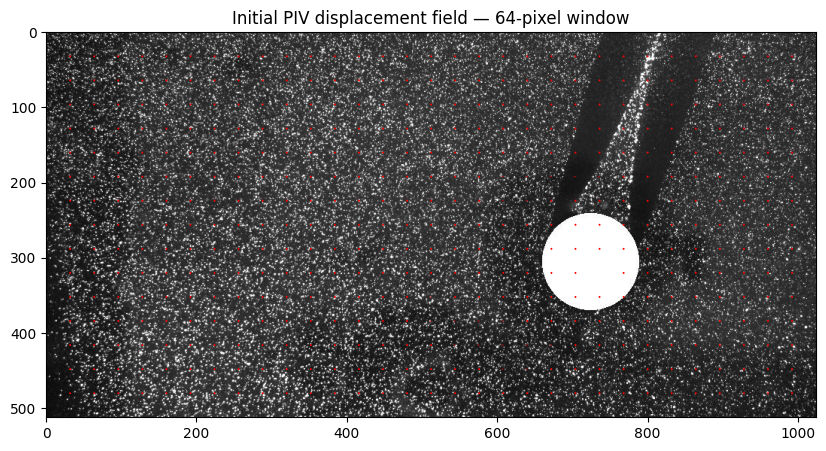

In [13]:
from openpiv import pyprocess
import numpy as np
import matplotlib.pyplot as plt

window_size = 64
overlap = 32
search_area_size = 64

u64, v64, s2n64 = pyprocess.extended_search_area_piv(
    frame_a.astype(np.int32),
    frame_b.astype(np.int32),
    window_size=window_size,
    overlap=overlap,
    dt=1.0,
    search_area_size=search_area_size,
    sig2noise_method="peak2peak"
)

print("Grid shape:", u64.shape)
print("Median SNR:", np.nanmedian(s2n64))
print("Maximum SNR:", np.nanmax(s2n64))

plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")

x64, y64 = pyprocess.get_coordinates(
    image_size=frame_a.shape,
    search_area_size=window_size,
    overlap=overlap
)

plt.quiver(
    x64, y64, u64, -v64,
    color="red", angles="xy",
    scale_units="xy", scale=1
)
plt.title("Initial PIV displacement field — 64-pixel window")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.show()

In [14]:
import os

notebook_path = (
    "/content/openpiv-python-examples-main/"
    "notebooks/openpiv_bridgepile_wake.ipynb"
)

print("Notebook exists:", os.path.exists(notebook_path))

Notebook exists: True


In [15]:
import json

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if any(term in source.lower() for term in [
            "extended_search_area_piv",
            "windef",
            "sig2noise",
            "threshold",
            "window_size"
        ]):
            print(f"\n--- Code cell {i} ---\n")
            print(source[:2500])


--- Code cell 4 ---

# %pdb
# np.seterr(all="raise")
winsize = 24 # pixels
searchsize = 48  # pixels, search in image B
overlap = 12 # pixels
dt = 1./30 # sec, assume 30 fps

frame_a[:600,:] = 0  # basically masking out the non-illuminated region
frame_b[:600,:] = 0


u0, v0, sig2noise = pyprocess.extended_search_area_piv(frame_a.astype(np.int32), 
                                                       frame_b.astype(np.int32), 
                                                       window_size=winsize, 
                                                       overlap=overlap, dt=dt, 
                                                       search_area_size=searchsize, 
                                                       sig2noise_method='peak2peak',
                                                      correlation_method='linear',
                                                      normalized_correlation=True)

--- Code cell 6 ---

mask = validation.sig2noise_val(sig2noise, threshol

Grid shape: (13, 28)
Coordinate shape: (13, 28)
Median SNR: 3.5082414366205597
Maximum SNR: 5.905277130410917


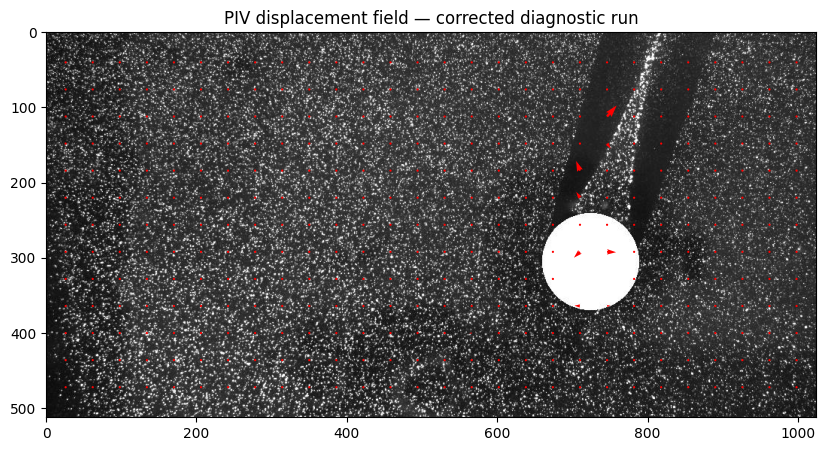

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from openpiv import pyprocess

# Reload fresh copies of the original images
frame_a_ref = frame_a.copy().astype(np.int32)
frame_b_ref = frame_b.copy().astype(np.int32)

# The images are 512 pixels tall, so do not mask the top 600 rows.
# Instead, leave the images intact for this diagnostic run.

winsize = 24
searchsize = 48
overlap = 12

u_ref, v_ref, s2n_ref = pyprocess.extended_search_area_piv(
    frame_a_ref,
    frame_b_ref,
    window_size=winsize,
    overlap=overlap,
    dt=1.0,
    search_area_size=searchsize,
    sig2noise_method="peak2peak",
    correlation_method="linear",
    normalized_correlation=True
)

# Coordinates must match the search-area grid returned by PIV.
x_ref, y_ref = pyprocess.get_coordinates(
    image_size=frame_a_ref.shape,
    search_area_size=searchsize,
    overlap=overlap
)

print("Grid shape:", u_ref.shape)
print("Coordinate shape:", x_ref.shape)
print("Median SNR:", np.nanmedian(s2n_ref))
print("Maximum SNR:", np.nanmax(s2n_ref))

plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")
plt.quiver(
    x_ref, y_ref, u_ref, -v_ref,
    color="red", angles="xy",
    scale_units="xy", scale=1
)
plt.title("PIV displacement field — corrected diagnostic run")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.show()

Total vectors: 364
Flagged vectors: 25
Invalid fraction: 6.87 %


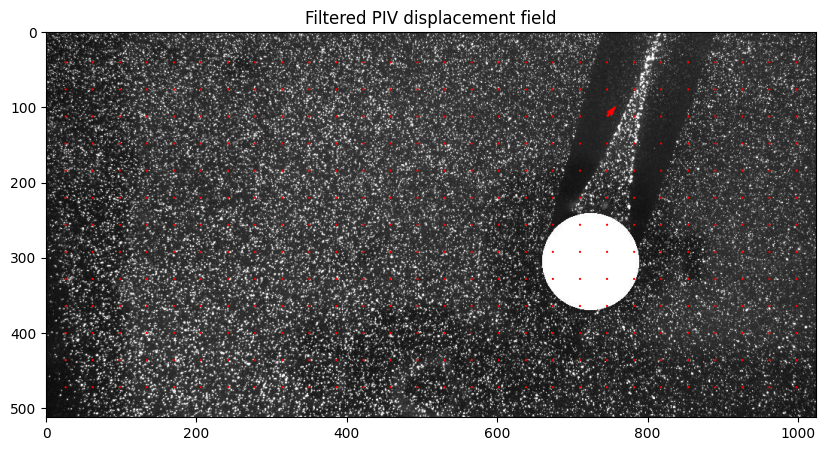

In [17]:
from openpiv import validation, filters
import numpy as np
import matplotlib.pyplot as plt

# Identify low-SNR vectors
invalid_ref = validation.sig2noise_val(
    s2n_ref, threshold=1.3
)

print("Total vectors:", invalid_ref.size)
print("Flagged vectors:", np.count_nonzero(invalid_ref))
print(
    "Invalid fraction:",
    round(100 * np.mean(invalid_ref), 2),
    "%"
)

# Replace flagged vectors with estimates from neighbouring valid vectors
u_clean_ref, v_clean_ref = filters.replace_outliers(
    u_ref, v_ref, invalid_ref,
    method="localmean",
    max_iter=5,
    kernel_size=3
)

# Plot the filtered displacement field
plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")
plt.quiver(
    x_ref, y_ref, u_clean_ref, -v_clean_ref,
    color="red", angles="xy",
    scale_units="xy", scale=1
)
plt.title("Filtered PIV displacement field")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.show()

Raw median displacement: 2.219 pixels
Filtered median displacement: 2.197 pixels
Filtered maximum displacement: 19.496 pixels


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


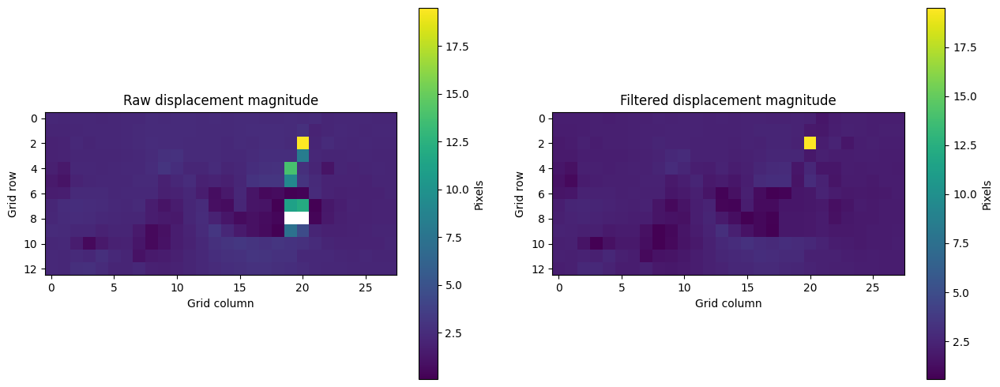

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Displacement magnitude, in pixels per image pair
magnitude_raw = np.sqrt(u_ref**2 + v_ref**2)
magnitude_clean = np.sqrt(u_clean_ref**2 + v_clean_ref**2)

print("Raw median displacement:",
      round(float(np.nanmedian(magnitude_raw)), 3), "pixels")

print("Filtered median displacement:",
      round(float(np.nanmedian(magnitude_clean)), 3), "pixels")

print("Filtered maximum displacement:",
      round(float(np.nanmax(magnitude_clean)), 3), "pixels")

# Display displacement magnitude
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im0 = axes[0].imshow(magnitude_raw, origin="upper", cmap="viridis")
axes[0].set_title("Raw displacement magnitude")
fig.colorbar(im0, ax=axes[0], label="Pixels")

im1 = axes[1].imshow(magnitude_clean, origin="upper", cmap="viridis")
axes[1].set_title("Filtered displacement magnitude")
fig.colorbar(im1, ax=axes[1], label="Pixels")

for ax in axes:
    ax.set_xlabel("Grid column")
    ax.set_ylabel("Grid row")

plt.tight_layout()
plt.show()

Valid filtered vectors: 364
Median displacement: 2.197 pixels
95th percentile: 2.855 pixels
Maximum displacement: 19.496 pixels


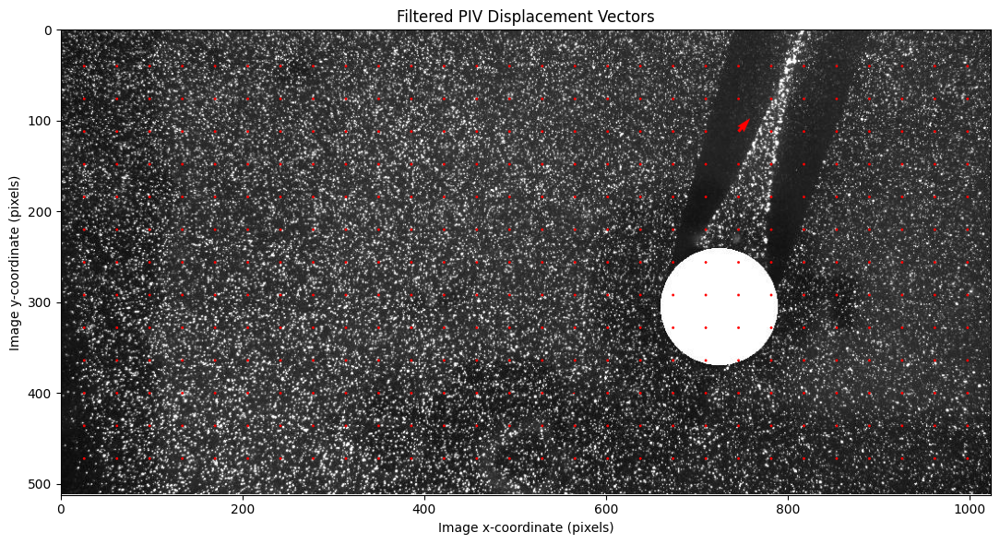

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Convert masked arrays safely; masked values become NaN
u_plot = np.ma.filled(np.ma.asarray(u_clean_ref), np.nan)
v_plot = np.ma.filled(np.ma.asarray(v_clean_ref), np.nan)

# Displacement magnitude
magnitude = np.sqrt(u_plot**2 + v_plot**2)

print("Valid filtered vectors:", np.count_nonzero(np.isfinite(magnitude)))
print("Median displacement:", round(float(np.nanmedian(magnitude)), 3), "pixels")
print("95th percentile:", round(float(np.nanpercentile(magnitude, 95)), 3), "pixels")
print("Maximum displacement:", round(float(np.nanmax(magnitude)), 3), "pixels")

plt.figure(figsize=(13, 6))
plt.imshow(frame_a, cmap="gray", origin="upper")

plt.quiver(
    x_ref, y_ref,
    u_plot, -v_plot,
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1
)

plt.title("Filtered PIV Displacement Vectors")
plt.xlabel("Image x-coordinate (pixels)")
plt.ylabel("Image y-coordinate (pixels)")
plt.xlim(0, frame_a.shape[1])
plt.ylim(frame_a.shape[0], 0)
plt.tight_layout()
plt.show()

In [20]:
import numpy as np

u_plot = np.ma.filled(np.ma.asarray(u_clean_ref), np.nan)
v_plot = np.ma.filled(np.ma.asarray(v_clean_ref), np.nan)

magnitude = np.sqrt(u_plot**2 + v_plot**2)

# Find the five largest displacement magnitudes
flat_indices = np.argsort(np.nan_to_num(magnitude, nan=-np.inf).ravel())[-5:][::-1]
rows, cols = np.unravel_index(flat_indices, magnitude.shape)

print("Five largest displacement vectors:")
for rank, (r, c) in enumerate(zip(rows, cols), start=1):
    print(
        f"{rank}. Grid row={r}, column={c}, "
        f"x={x_ref[r, c]:.1f} px, y={y_ref[r, c]:.1f} px, "
        f"|displacement|={magnitude[r, c]:.3f} px"
    )

Five largest displacement vectors:
1. Grid row=2, column=20, x=746.0 px, y=112.0 px, |displacement|=19.496 px
2. Grid row=10, column=15, x=566.0 px, y=400.0 px, |displacement|=3.249 px
3. Grid row=9, column=13, x=494.0 px, y=364.0 px, |displacement|=3.149 px
4. Grid row=5, column=18, x=674.0 px, y=220.0 px, |displacement|=3.084 px
5. Grid row=5, column=17, x=638.0 px, y=220.0 px, |displacement|=3.081 px


Suspicious vector:
u = 12.83385503221799 pixels
v = 14.675695542572463 pixels
Magnitude = 19.495739910202644 pixels
Signal-to-noise ratio = 1.3829239166444


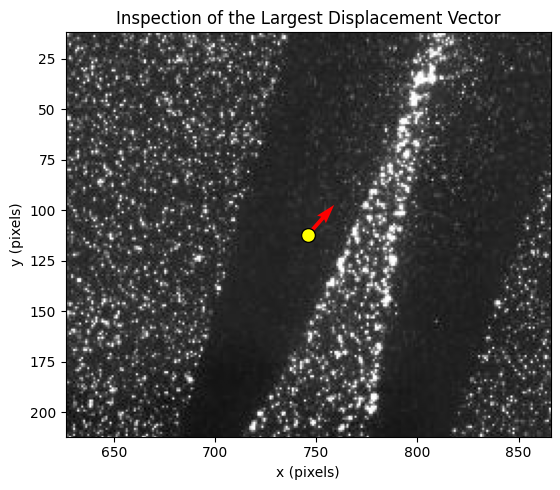

In [21]:
import numpy as np
import matplotlib.pyplot as plt

r, c = 2, 20

print("Suspicious vector:")
print("u =", float(u_plot[r, c]), "pixels")
print("v =", float(v_plot[r, c]), "pixels")
print("Magnitude =", float(magnitude[r, c]), "pixels")
print("Signal-to-noise ratio =", float(s2n_ref[r, c]))

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(frame_a, cmap="gray", origin="upper")

# Show the suspicious vector in red
ax.quiver(
    x_ref[r, c], y_ref[r, c],
    u_plot[r, c], -v_plot[r, c],
    color="red", angles="xy",
    scale_units="xy", scale=1,
    width=0.008
)

# Mark its measurement location
ax.scatter(
    x_ref[r, c], y_ref[r, c],
    color="yellow", edgecolors="black", s=100
)

ax.set_xlim(x_ref[r, c] - 120, x_ref[r, c] + 120)
ax.set_ylim(y_ref[r, c] + 100, y_ref[r, c] - 100)
ax.set_title("Inspection of the Largest Displacement Vector")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
plt.tight_layout()
plt.show()

In [22]:
r, c = 2, 20

print("Original vector:")
print(f"u = {float(u_ref[r, c]):.3f} px")
print(f"v = {float(v_ref[r, c]):.3f} px")
print(f"Magnitude = {float(np.sqrt(u_ref[r, c]**2 + v_ref[r, c]**2)):.3f} px")

print("\nAfter outlier replacement:")
print(f"u = {float(u_clean_ref[r, c]):.3f} px")
print(f"v = {float(v_clean_ref[r, c]):.3f} px")

print("\nWas it flagged initially?", bool(invalid_ref[r, c]))

Original vector:
u = 12.834 px
v = 14.676 px
Magnitude = 19.496 px

After outlier replacement:
u = 12.834 px
v = 14.676 px

Was it flagged initially? False


In [23]:
r, c = 2, 20

print("Local displacement field (pixels)")
print("Each entry shows: (u, v, magnitude)\n")

for i in range(max(0, r - 2), min(u_ref.shape[0], r + 3)):
    for j in range(max(0, c - 2), min(u_ref.shape[1], c + 3)):
        uu = float(u_ref[i, j])
        vv = float(v_ref[i, j])
        mag = float(np.sqrt(uu**2 + vv**2))

        marker = "  <-- suspicious vector" if (i == r and j == c) else ""
        print(
            f"row={i:2d}, col={j:2d}: "
            f"({uu:7.2f}, {vv:7.2f}), "
            f"|d|={mag:6.2f}{marker}"
        )
    print()

Local displacement field (pixels)
Each entry shows: (u, v, magnitude)

row= 0, col=18: (  -2.38,   -0.03), |d|=  2.38
row= 0, col=19: (  -2.46,   -0.15), |d|=  2.47
row= 0, col=20: (  -2.38,   -0.26), |d|=  2.39
row= 0, col=21: (  -2.44,   -0.11), |d|=  2.44
row= 0, col=22: (  -2.13,   -0.04), |d|=  2.13

row= 1, col=18: (  -2.50,   -0.19), |d|=  2.51
row= 1, col=19: (  -2.46,   -0.10), |d|=  2.46
row= 1, col=20: (  -2.74,   -0.42), |d|=  2.77
row= 1, col=21: (  -1.98,   -0.05), |d|=  1.98
row= 1, col=22: (  -2.19,   -0.08), |d|=  2.19

row= 2, col=18: (  -2.50,   -0.09), |d|=  2.50
row= 2, col=19: (  -2.40,   -0.15), |d|=  2.41
row= 2, col=20: (  12.83,   14.68), |d|= 19.50  <-- suspicious vector
row= 2, col=21: (  -2.10,   -0.13), |d|=  2.11
row= 2, col=22: (  -2.37,   -0.51), |d|=  2.43

row= 3, col=18: (  -2.60,   -0.12), |d|=  2.60
row= 3, col=19: (  -2.61,   -0.26), |d|=  2.62
row= 3, col=20: (   4.84,   -6.69), |d|=  8.26
row= 3, col=21: (  -2.26,   -0.19), |d|=  2.27
row= 3, co

In [24]:
import numpy as np
from scipy.ndimage import median_filter

# Preserve masked/invalid values as NaN
u_original = np.ma.filled(np.ma.asarray(u_ref), np.nan)
v_original = np.ma.filled(np.ma.asarray(v_ref), np.nan)

# Replace NaNs temporarily for calculating local medians
u_temp = np.nan_to_num(u_original, nan=0.0)
v_temp = np.nan_to_num(v_original, nan=0.0)

# Estimate local median displacement components
u_median = median_filter(u_temp, size=3, mode="nearest")
v_median = median_filter(v_temp, size=3, mode="nearest")

# Difference between measured and local-median vectors
residual = np.sqrt(
    (u_original - u_median)**2 +
    (v_original - v_median)**2
)

print("Local-median residuals near suspicious region:")
for i in range(1, 5):
    for j in range(18, 22):
        print(
            f"row={i}, col={j}: "
            f"residual={residual[i, j]:.2f} px"
        )

Local-median residuals near suspicious region:
row=1, col=18: residual=0.09 px
row=1, col=19: residual=0.05 px
row=1, col=20: residual=0.44 px
row=1, col=21: residual=0.22 px
row=2, col=18: residual=0.02 px
row=2, col=19: residual=0.10 px
row=2, col=20: residual=21.16 px
row=2, col=21: residual=0.06 px
row=3, col=18: residual=0.04 px
row=3, col=19: residual=0.13 px
row=3, col=20: residual=9.63 px
row=3, col=21: residual=0.24 px
row=4, col=18: residual=0.12 px
row=4, col=19: residual=13.16 px
row=4, col=20: residual=0.06 px
row=4, col=21: residual=0.03 px


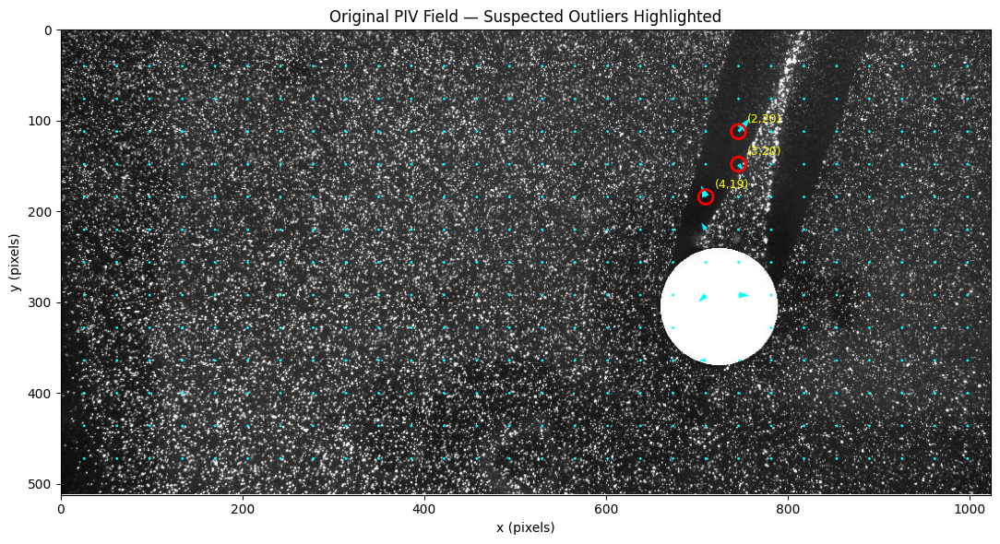

In [25]:
import numpy as np
import matplotlib.pyplot as plt

u_original = np.ma.filled(np.ma.asarray(u_ref), np.nan)
v_original = np.ma.filled(np.ma.asarray(v_ref), np.nan)

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(frame_a, cmap="gray", origin="upper")

# Plot all original vectors
ax.quiver(
    x_ref, y_ref,
    u_original, -v_original,
    color="cyan",
    angles="xy",
    scale_units="xy",
    scale=1
)

# Highlight the three candidate outliers
candidate_points = [(2, 20), (3, 20), (4, 19)]

for r, c in candidate_points:
    ax.scatter(
        x_ref[r, c], y_ref[r, c],
        s=130,
        facecolors="none",
        edgecolors="red",
        linewidths=2
    )
    ax.annotate(
        f"({r},{c})",
        (x_ref[r, c], y_ref[r, c]),
        xytext=(7, 7),
        textcoords="offset points",
        color="yellow",
        fontsize=9
    )

ax.set_title("Original PIV Field — Suspected Outliers Highlighted")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
ax.set_xlim(0, frame_a.shape[1])
ax.set_ylim(frame_a.shape[0], 0)

plt.tight_layout()
plt.show()

Candidate vectors flagged: 3
Remaining finite vectors: 359
Median displacement after flagging: 2.213 pixels


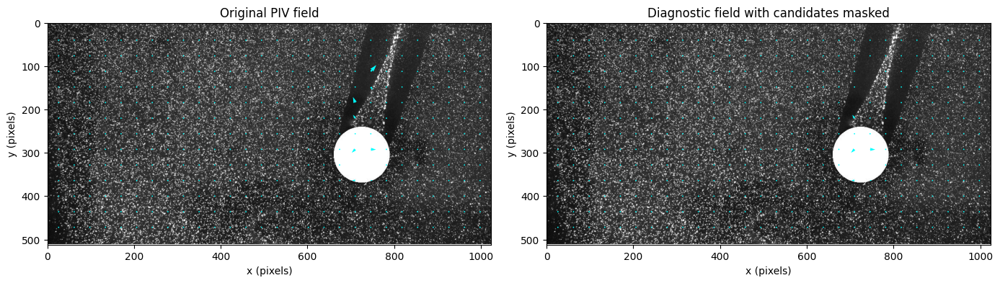

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Copy original measurements; do not modify u_ref or v_ref
u_flagged = np.ma.filled(np.ma.asarray(u_ref), np.nan).copy()
v_flagged = np.ma.filled(np.ma.asarray(v_ref), np.nan).copy()

# Candidate outliers identified by the local-median check
candidate_points = [(2, 20), (3, 20), (4, 19)]

for r, c in candidate_points:
    u_flagged[r, c] = np.nan
    v_flagged[r, c] = np.nan

magnitude_flagged = np.sqrt(u_flagged**2 + v_flagged**2)

print("Candidate vectors flagged:", len(candidate_points))
print("Remaining finite vectors:", np.count_nonzero(np.isfinite(magnitude_flagged)))
print("Median displacement after flagging:",
      round(float(np.nanmedian(magnitude_flagged)), 3), "pixels")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(frame_a, cmap="gray", origin="upper")
axes[0].quiver(
    x_ref, y_ref, u_original, -v_original,
    color="cyan", angles="xy", scale_units="xy", scale=1
)
axes[0].set_title("Original PIV field")

axes[1].imshow(frame_a, cmap="gray", origin="upper")
axes[1].quiver(
    x_ref, y_ref, u_flagged, -v_flagged,
    color="cyan", angles="xy", scale_units="xy", scale=1
)
axes[1].set_title("Diagnostic field with candidates masked")

for ax in axes:
    ax.set_xlim(0, frame_a.shape[1])
    ax.set_ylim(frame_a.shape[0], 0)
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
from scipy.ndimage import median_filter

# Start from the original field
u_clean_final = np.ma.filled(np.ma.asarray(u_ref), np.nan).copy()
v_clean_final = np.ma.filled(np.ma.asarray(v_ref), np.nan).copy()

# Count original finite entries
original_finite = np.isfinite(u_clean_final) & np.isfinite(v_clean_final)
print("Original finite vectors:", np.count_nonzero(original_finite))

# Estimate local medians from the original field
u_for_median = np.nan_to_num(u_clean_final, nan=0.0)
v_for_median = np.nan_to_num(v_clean_final, nan=0.0)

u_local = median_filter(u_for_median, size=3, mode="nearest")
v_local = median_filter(v_for_median, size=3, mode="nearest")

candidate_points = [(2, 20), (3, 20), (4, 19)]

for r, c in candidate_points:
    u_clean_final[r, c] = u_local[r, c]
    v_clean_final[r, c] = v_local[r, c]

magnitude_final = np.sqrt(u_clean_final**2 + v_clean_final**2)

print("Finite vectors after replacement:",
      np.count_nonzero(np.isfinite(magnitude_final)))
print("Final median displacement:",
      round(float(np.nanmedian(magnitude_final)), 3), "pixels")

for r, c in candidate_points:
    print(
        f"Grid ({r}, {c}): "
        f"u={u_clean_final[r,c]:.3f}, "
        f"v={v_clean_final[r,c]:.3f}, "
        f"magnitude={magnitude_final[r,c]:.3f} px"
    )

Original finite vectors: 362
Finite vectors after replacement: 362
Final median displacement: 2.219 pixels
Grid (2, 20): u=-2.259, v=-0.153, magnitude=2.265 px
Grid (3, 20): u=-2.259, v=-0.191, magnitude=2.267 px
Grid (4, 19): u=-2.861, v=-0.125, magnitude=2.864 px


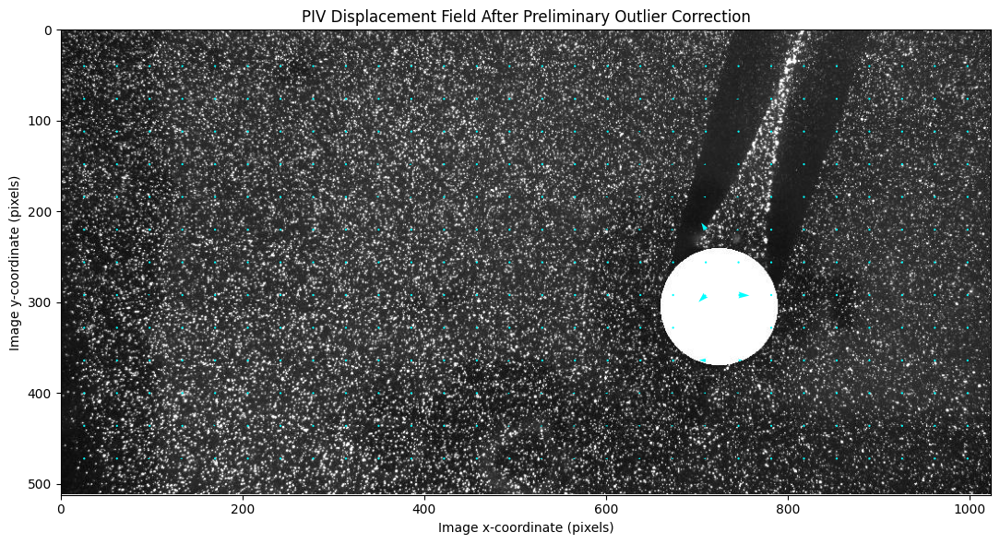

Saved figure: cleaned_piv_displacement.png


In [28]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 6))

ax.imshow(frame_a, cmap="gray", origin="upper")

ax.quiver(
    x_ref, y_ref,
    u_clean_final, -v_clean_final,
    color="cyan",
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.0025
)

ax.set_title("PIV Displacement Field After Preliminary Outlier Correction")
ax.set_xlabel("Image x-coordinate (pixels)")
ax.set_ylabel("Image y-coordinate (pixels)")
ax.set_xlim(0, frame_a.shape[1])
ax.set_ylim(frame_a.shape[0], 0)

plt.tight_layout()
plt.savefig("cleaned_piv_displacement.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure: cleaned_piv_displacement.png")

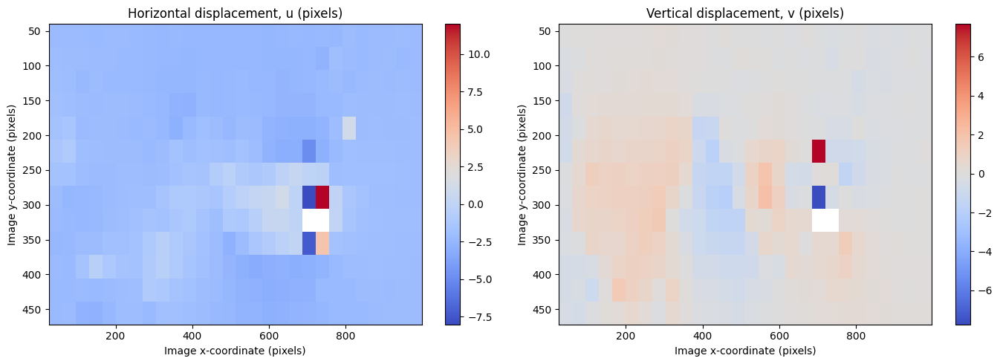

In [29]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plots = [
    (u_clean_final, "Horizontal displacement, u (pixels)"),
    (v_clean_final, "Vertical displacement, v (pixels)")
]

for ax, (field, title) in zip(axes, plots):
    im = ax.imshow(
        field,
        origin="upper",
        extent=[x_ref.min(), x_ref.max(), y_ref.max(), y_ref.min()],
        cmap="coolwarm",
        aspect="auto"
    )
    ax.set_title(title)
    ax.set_xlabel("Image x-coordinate (pixels)")
    ax.set_ylabel("Image y-coordinate (pixels)")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

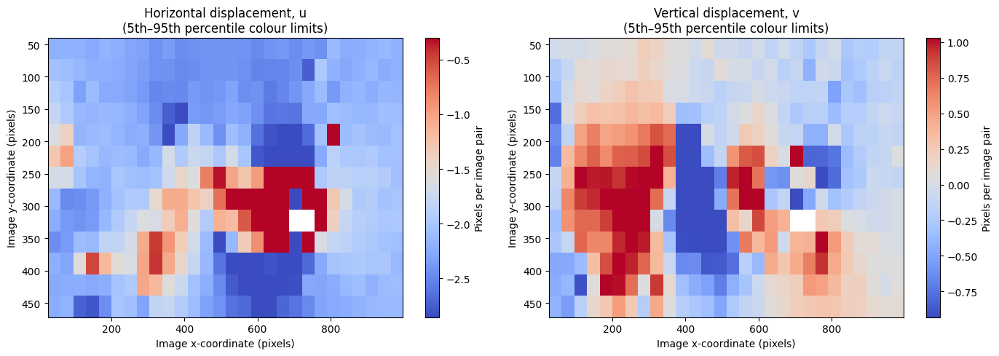

In [30]:
import numpy as np
import matplotlib.pyplot as plt

fields = [
    (u_clean_final, "Horizontal displacement, u"),
    (v_clean_final, "Vertical displacement, v")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (field, title) in zip(axes, fields):
    field_array = np.asarray(field, dtype=float)
    finite = field_array[np.isfinite(field_array)]

    vmin, vmax = np.percentile(finite, [5, 95])

    im = ax.imshow(
        field_array,
        origin="upper",
        extent=[x_ref.min(), x_ref.max(), y_ref.max(), y_ref.min()],
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    ax.set_title(title + "\n(5th–95th percentile colour limits)")
    ax.set_xlabel("Image x-coordinate (pixels)")
    ax.set_ylabel("Image y-coordinate (pixels)")
    fig.colorbar(im, ax=ax, label="Pixels per image pair")

plt.tight_layout()
plt.show()

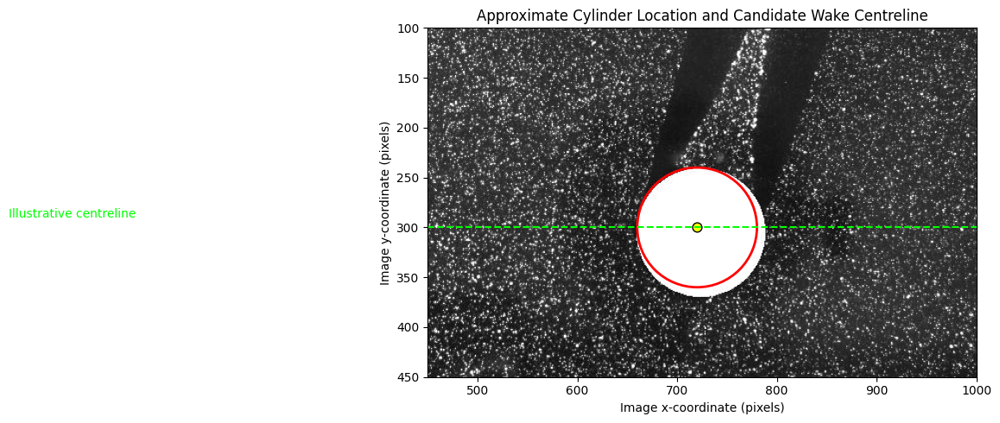

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.imshow(frame_a, cmap="gray", origin="upper")

# Approximate cylinder centre
cx, cy, radius = 720, 300, 60

circle = plt.Circle(
    (cx, cy), radius,
    edgecolor="red", facecolor="none", linewidth=2
)
plt.gca().add_patch(circle)
plt.scatter(cx, cy, color="yellow", edgecolors="black", s=60)

# Illustrative downstream sampling line
plt.axhline(cy, color="lime", linestyle="--", linewidth=1.5)
plt.text(30, cy - 10, "Illustrative centreline", color="lime")

plt.xlim(450, 1000)
plt.ylim(450, 100)
plt.xlabel("Image x-coordinate (pixels)")
plt.ylabel("Image y-coordinate (pixels)")
plt.title("Approximate Cylinder Location and Candidate Wake Centreline")
plt.tight_layout()
plt.show()

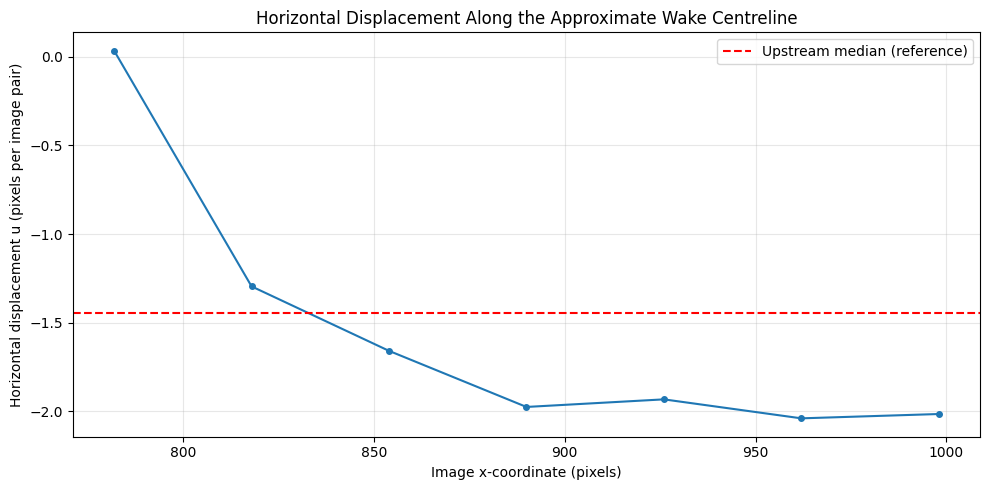

Sampling grid row: 7
Number of downstream points: 7


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Approximate cylinder geometry, in image pixels
cx, cy, radius = 720, 300, 60

# Select the PIV grid row nearest the centreline
row = np.argmin(np.abs(y_ref[:, 0] - cy))

x_profile = x_ref[row, :]
u_profile = u_clean_final[row, :]

# Keep finite values downstream of the cylinder's right edge
valid = (
    np.isfinite(u_profile)
    & (x_profile > cx + radius)
)

x_wake = x_profile[valid]
u_wake = u_profile[valid]

plt.figure(figsize=(10, 5))
plt.plot(x_wake, u_wake, "o-", markersize=4)
plt.axhline(
    np.nanmedian(u_profile[x_profile < cx - radius]),
    color="red",
    linestyle="--",
    label="Upstream median (reference)"
)

plt.xlabel("Image x-coordinate (pixels)")
plt.ylabel("Horizontal displacement u (pixels per image pair)")
plt.title("Horizontal Displacement Along the Approximate Wake Centreline")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Sampling grid row:", row)
print("Number of downstream points:", len(x_wake))

In [33]:
print("Downstream centreline profile")
print("-" * 42)

for x_value, u_value in zip(x_wake, u_wake):
    print(f"x = {x_value:7.1f} px | u = {u_value:8.3f} px/frame")

Downstream centreline profile
------------------------------------------
x =   782.0 px | u =    0.035 px/frame
x =   818.0 px | u =   -1.296 px/frame
x =   854.0 px | u =   -1.660 px/frame
x =   890.0 px | u =   -1.976 px/frame
x =   926.0 px | u =   -1.933 px/frame
x =   962.0 px | u =   -2.041 px/frame
x =   998.0 px | u =   -2.016 px/frame


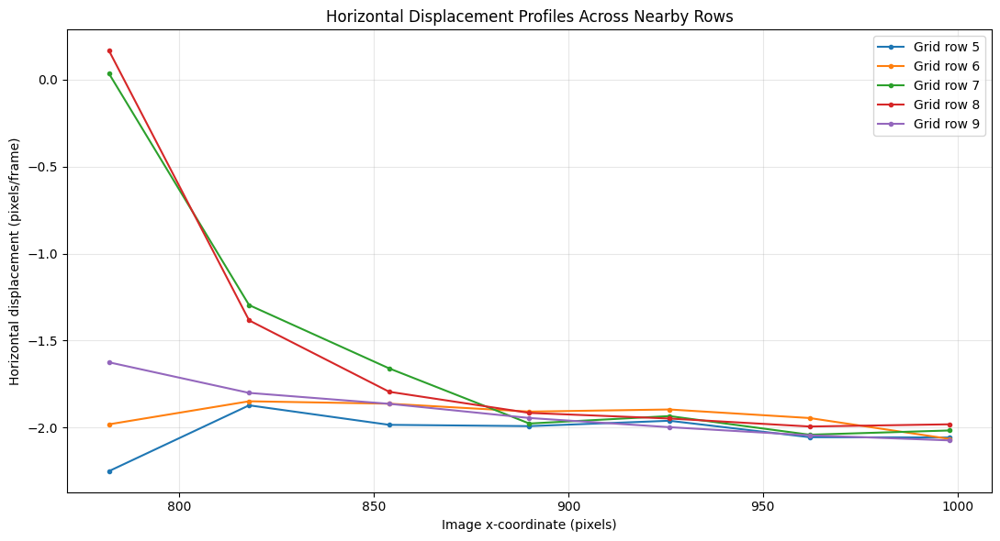

In [34]:
import numpy as np
import matplotlib.pyplot as plt

cx, cy, radius = 720, 300, 60

# Five rows around the approximate cylinder centreline
centre_row = np.argmin(np.abs(y_ref[:, 0] - cy))
rows_to_plot = range(
    max(0, centre_row - 2),
    min(u_clean_final.shape[0], centre_row + 3)
)

plt.figure(figsize=(11, 6))

for row in rows_to_plot:
    x_row = x_ref[row, :]
    u_row = u_clean_final[row, :]

    valid = (
        np.isfinite(u_row)
        & (x_row > cx + radius)
    )

    plt.plot(
        x_row[valid],
        u_row[valid],
        marker="o",
        markersize=3,
        label=f"Grid row {row}"
    )

plt.xlabel("Image x-coordinate (pixels)")
plt.ylabel("Horizontal displacement (pixels/frame)")
plt.title("Horizontal Displacement Profiles Across Nearby Rows")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

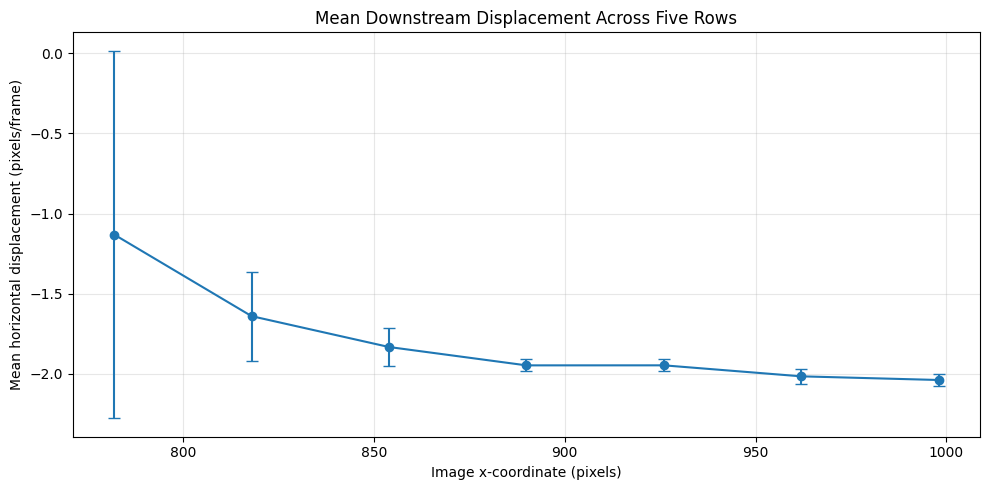

x (px) | mean u (px/frame) | standard deviation
 782.0 |            -1.131 | 1.147
 818.0 |            -1.640 | 0.277
 854.0 |            -1.833 | 0.118
 890.0 |            -1.947 | 0.037
 926.0 |            -1.947 | 0.037
 962.0 |            -2.016 | 0.046
 998.0 |            -2.038 | 0.039


In [35]:
import numpy as np
import matplotlib.pyplot as plt

cx, cy, radius = 720, 300, 60

centre_row = np.argmin(np.abs(y_ref[:, 0] - cy))
rows_to_plot = range(
    max(0, centre_row - 2),
    min(u_clean_final.shape[0], centre_row + 3)
)

x_values = []
mean_u = []
std_u = []

for col in range(u_clean_final.shape[1]):
    x_here = x_ref[centre_row, col]

    if x_here <= cx + radius:
        continue

    values = np.array([
        u_clean_final[row, col]
        for row in rows_to_plot
    ], dtype=float)

    values = values[np.isfinite(values)]

    if len(values) >= 3:
        x_values.append(x_here)
        mean_u.append(np.mean(values))
        std_u.append(np.std(values, ddof=1))

x_values = np.array(x_values)
mean_u = np.array(mean_u)
std_u = np.array(std_u)

plt.figure(figsize=(10, 5))
plt.errorbar(
    x_values, mean_u, yerr=std_u,
    fmt="o-", capsize=4
)
plt.xlabel("Image x-coordinate (pixels)")
plt.ylabel("Mean horizontal displacement (pixels/frame)")
plt.title("Mean Downstream Displacement Across Five Rows")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("x (px) | mean u (px/frame) | standard deviation")
for x, m, s in zip(x_values, mean_u, std_u):
    print(f"{x:6.1f} | {m:17.3f} | {s:.3f}")

In [36]:
import pandas as pd

results_df = pd.DataFrame({
    "x_pixels": x_values,
    "mean_u_pixels_per_frame": mean_u,
    "std_u_pixels_per_frame": std_u
})

results_df.to_csv("downstream_displacement_profile.csv", index=False)

print(results_df.to_string(index=False))
print("\nSaved: downstream_displacement_profile.csv")

 x_pixels  mean_u_pixels_per_frame  std_u_pixels_per_frame
    782.0                -1.130781                1.146794
    818.0                -1.639918                0.277134
    854.0                -1.832555                0.118434
    890.0                -1.947059                0.036619
    926.0                -1.946867                0.037223
    962.0                -2.015515                0.046050
    998.0                -2.038370                0.038930

Saved: downstream_displacement_profile.csv


In [37]:
readme = r"""
# PIV-Based Cylinder Wake Analysis

## Project Overview
This project explores particle image velocimetry (PIV) processing using
Python and OpenPIV. An image pair containing a circular obstacle is analysed
to estimate particle-image displacement fields and examine their spatial
variation downstream of the obstacle.

## Tools
- Python
- NumPy
- Matplotlib
- OpenPIV
- Pandas

## Methodology
1. Load the two images as grayscale arrays.
2. Estimate displacement using OpenPIV extended-search-area PIV.
3. Apply signal-to-noise validation.
4. Investigate unusually large vectors using a local-median comparison.
5. Create a separate diagnostic field with three candidate outliers replaced
   by local-median estimates.
6. Plot horizontal and vertical displacement components.
7. Compare horizontal displacement across five neighbouring grid rows.
8. Export the downstream profile statistics to CSV.

## Preliminary Processing Settings
- Window size: 24 pixels
- Search area size: 48 pixels
- Overlap: 12 pixels
- Correlation method: linear
- Normalized correlation: enabled
- Signal-to-noise screening threshold: 1.3

## Preliminary Observation
Across five selected grid rows, the mean horizontal image displacement
becomes more consistent at downstream sample positions. At x = 998 pixels,
the mean is approximately -2.038 pixels per image pair, with a
between-row standard deviation of approximately 0.039 pixels per image pair.

These are preliminary image-displacement statistics, not calibrated flow
velocities or proof of wake recovery.

## Limitations and Next Steps
- Verify the dataset's provenance and the physical meaning of the image pair.
- Establish the actual frame interval and spatial calibration before
  calculating velocities in physical units.
- Investigate masked regions and correlation quality near the obstacle.
- Validate outlier detection and replacement against the raw measurements.
- Compare the measured field with an appropriate reference dataset or
  published benchmark before making physical claims.

## Output
- `downstream_displacement_profile.csv`

## Reproducibility
The analysis is being developed in Google Colab. The notebook and figures
should be committed alongside the output data, with the dataset source
and applicable licence documented.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip() + "\n")

print("README.md created successfully!")
print(readme)

README.md created successfully!

# PIV-Based Cylinder Wake Analysis

## Project Overview
This project explores particle image velocimetry (PIV) processing using
Python and OpenPIV. An image pair containing a circular obstacle is analysed
to estimate particle-image displacement fields and examine their spatial
variation downstream of the obstacle.

## Tools
- Python
- NumPy
- Matplotlib
- OpenPIV
- Pandas

## Methodology
1. Load the two images as grayscale arrays.
2. Estimate displacement using OpenPIV extended-search-area PIV.
3. Apply signal-to-noise validation.
4. Investigate unusually large vectors using a local-median comparison.
5. Create a separate diagnostic field with three candidate outliers replaced
   by local-median estimates.
6. Plot horizontal and vertical displacement components.
7. Compare horizontal displacement across five neighbouring grid rows.
8. Export the downstream profile statistics to CSV.

## Preliminary Processing Settings
- Window size: 24 pixels
- Search a

In [38]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
from google.colab import files
files.download("downstream_displacement_profile.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
from google.colab import files
files.download("cleaned_piv_displacement.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import numpy as np

# Check the final displacement field
valid = np.isfinite(u_clean_final) & np.isfinite(v_clean_final)

magnitude = np.sqrt(
    u_clean_final[valid]**2 +
    v_clean_final[valid]**2
)

print("Total vectors:", u_clean_final.size)
print("Finite vectors:", valid.sum())
print("Invalid or missing vectors:", (~valid).sum())
print("Median displacement (pixels/frame):",
      np.median(magnitude))
print("95th percentile displacement (pixels/frame):",
      np.percentile(magnitude, 95))

Total vectors: 364
Finite vectors: 362
Invalid or missing vectors: 2
Median displacement (pixels/frame): 2.219206139094636
95th percentile displacement (pixels/frame): 2.876438018100476


In [42]:
# Show the displacement-related variables currently available
for name in sorted(globals()):
    if any(key in name.lower() for key in ["u_clean", "v_clean", "u_ref", "v_ref", "u_", "v_"]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(name, obj.shape)

u_clean (31, 63)
u_clean_final (13, 28)
u_clean_ref (13, 28)
u_flagged (13, 28)
u_for_median (13, 28)
u_local (13, 28)
u_median (13, 28)
u_original (13, 28)
u_plot (13, 28)
u_profile (28,)
u_ref (13, 28)
u_row (28,)
u_temp (13, 28)
u_value ()
u_wake (7,)
v_clean (31, 63)
v_clean_final (13, 28)
v_clean_ref (13, 28)
v_flagged (13, 28)
v_for_median (13, 28)
v_local (13, 28)
v_median (13, 28)
v_original (13, 28)
v_plot (13, 28)
v_ref (13, 28)
v_temp (13, 28)


In [43]:
import numpy as np

# Original and corrected displacement fields
u_raw = np.asarray(u_ref, dtype=float)
v_raw = np.asarray(v_ref, dtype=float)
u_corr = np.asarray(u_clean_final, dtype=float)
v_corr = np.asarray(v_clean_final, dtype=float)

assert u_raw.shape == u_corr.shape
assert v_raw.shape == v_corr.shape

raw_valid = np.isfinite(u_raw) & np.isfinite(v_raw)
corr_valid = np.isfinite(u_corr) & np.isfinite(v_corr)

raw_mag = np.hypot(u_raw, v_raw)
corr_mag = np.hypot(u_corr, v_corr)

print("Raw finite vectors:", raw_valid.sum(), "/", raw_valid.size)
print("Corrected finite vectors:", corr_valid.sum(), "/", corr_valid.size)

print("\nRaw median magnitude:",
      np.nanmedian(np.where(raw_valid, raw_mag, np.nan)))
print("Corrected median magnitude:",
      np.nanmedian(np.where(corr_valid, corr_mag, np.nan)))

print("\nRaw 95th percentile:",
      np.nanpercentile(np.where(raw_valid, raw_mag, np.nan), 95))
print("Corrected 95th percentile:",
      np.nanpercentile(np.where(corr_valid, corr_mag, np.nan), 95))

# Locations corrected manually in the earlier analysis
corrected_locations = [(2, 20), (3, 20), (4, 19)]

print("\nManually corrected locations:")
for r, c in corrected_locations:
    print(
        f"row={r}, col={c}: "
        f"raw=({u_raw[r,c]:.3f}, {v_raw[r,c]:.3f}), "
        f"corrected=({u_corr[r,c]:.3f}, {v_corr[r,c]:.3f})"
    )

Raw finite vectors: 362 / 364
Corrected finite vectors: 362 / 364

Raw median magnitude: 2.2192061390946365
Corrected median magnitude: 2.2192061390946365

Raw 95th percentile: 2.9615147744943373
Corrected 95th percentile: 2.876438018100476

Manually corrected locations:
row=2, col=20: raw=(12.834, 14.676), corrected=(-2.259, -0.153)
row=3, col=20: raw=(4.844, -6.689), corrected=(-2.259, -0.191)
row=4, col=19: raw=(-5.118, 12.841), corrected=(-2.861, -0.125)


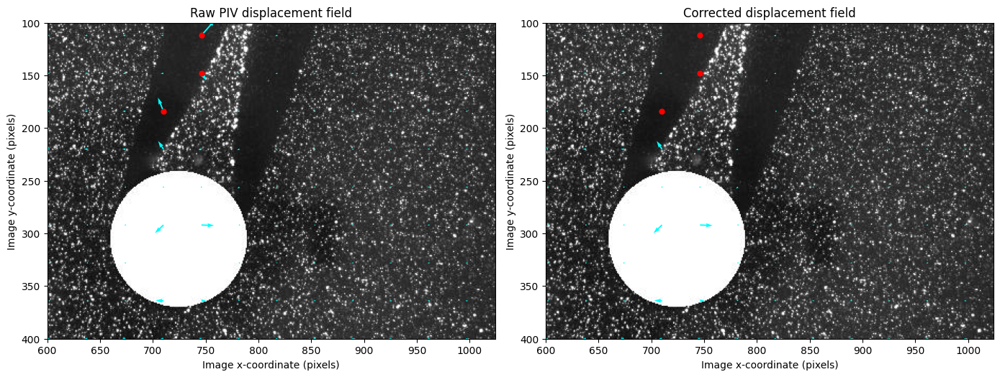

In [44]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fields = [
    (u_ref, v_ref, "Raw PIV displacement field"),
    (u_clean_final, v_clean_final, "Corrected displacement field")
]

for ax, (u_field, v_field, title) in zip(axes, fields):
    ax.imshow(frame_a, cmap="gray", origin="upper")

    ax.quiver(
        x_ref, y_ref,
        u_field, -v_field,
        color="cyan",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=0.003
    )

    for r, c in [(2, 20), (3, 20), (4, 19)]:
        ax.plot(x_ref[r, c], y_ref[r, c], "ro", markersize=5)

    ax.set_xlim(600, 1024)
    ax.set_ylim(400, 100)
    ax.set_title(title)
    ax.set_xlabel("Image x-coordinate (pixels)")
    ax.set_ylabel("Image y-coordinate (pixels)")

plt.tight_layout()
plt.show()

In [45]:
import numpy as np
from scipy.ndimage import generic_filter

u = np.asarray(u_clean_final, dtype=float)
v = np.asarray(v_clean_final, dtype=float)

# Use NaN-aware local medians
def nanmedian_filter(a):
    return generic_filter(
        a, np.nanmedian, size=3, mode="nearest"
    )

u_neighbours = nanmedian_filter(u)
v_neighbours = nanmedian_filter(v)

# Local difference between each vector and its neighbourhood
residual = np.hypot(u - u_neighbours, v - v_neighbours)

for r, c in [(2, 20), (3, 20), (4, 19)]:
    print(
        f"row={r}, col={c}: "
        f"corrected=({u[r,c]:.3f}, {v[r,c]:.3f}), "
        f"local median=({u_neighbours[r,c]:.3f}, "
        f"{v_neighbours[r,c]:.3f}), "
        f"difference={residual[r,c]:.3f} pixels/frame"
    )

row=2, col=20: corrected=(-2.259, -0.153), local median=(-2.259, -0.153), difference=0.000 pixels/frame
row=3, col=20: corrected=(-2.259, -0.191), local median=(-2.259, -0.191), difference=0.000 pixels/frame
row=4, col=19: corrected=(-2.861, -0.125), local median=(-2.861, -0.125), difference=0.000 pixels/frame


In [46]:
import numpy as np

u = np.asarray(u_clean_final, dtype=float)
v = np.asarray(v_clean_final, dtype=float)

def neighbour_median(a, r, c):
    r0, r1 = max(0, r-1), min(a.shape[0], r+2)
    c0, c1 = max(0, c-1), min(a.shape[1], c+2)

    patch = a[r0:r1, c0:c1].copy()
    patch[r-r0, c-c0] = np.nan  # exclude centre vector

    return np.nanmedian(patch)

for r, c in [(2, 20), (3, 20), (4, 19)]:
    um = neighbour_median(u, r, c)
    vm = neighbour_median(v, r, c)
    difference = np.hypot(u[r, c] - um, v[r, c] - vm)

    print(
        f"row={r}, col={c}: "
        f"corrected=({u[r,c]:.3f}, {v[r,c]:.3f}), "
        f"neighbour median=({um:.3f}, {vm:.3f}), "
        f"difference={difference:.3f} pixels/frame"
    )

row=2, col=20: corrected=(-2.259, -0.153), neighbour median=(-2.331, -0.172), difference=0.074 pixels/frame
row=3, col=20: corrected=(-2.259, -0.191), neighbour median=(-2.331, -0.172), difference=0.074 pixels/frame
row=4, col=19: corrected=(-2.861, -0.125), neighbour median=(-2.766, -0.158), difference=0.101 pixels/frame


In [47]:
import numpy as np

total = s2n_ref.size
flagged = np.asarray(invalid_ref, dtype=bool)

print("Total vectors:", total)
print("Flagged by SNR validation:", flagged.sum())
print("SNR-flagged percentage:", round(100 * flagged.mean(), 2), "%")
print("Non-finite raw vectors:",
      np.sum(~(np.isfinite(u_ref) & np.isfinite(v_ref))))

Total vectors: 364
Flagged by SNR validation: 25
SNR-flagged percentage: 6.87 %
Non-finite raw vectors: 2


In [48]:
import numpy as np
from openpiv import pyprocess

# Baseline: your existing 24 px window
u24, v24 = u_ref.copy(), v_ref.copy()

# Alternative: 16 px window, 32 px search area, 8 px overlap
u16, v16, s2n16 = pyprocess.extended_search_area_piv(
    frame_a.astype(np.int32),
    frame_b.astype(np.int32),
    window_size=16,
    overlap=8,
    dt=1.0,
    search_area_size=32,
    sig2noise_method="peak2peak",
    correlation_method="linear",
    normalized_correlation=True
)

print("Baseline grid:", u24.shape)
print("Alternative grid:", u16.shape)
print("Alternative median SNR:", np.nanmedian(s2n16))

Baseline grid: (13, 28)
Alternative grid: (21, 42)
Alternative median SNR: 2.507890044273224


In [50]:
import numpy as np
from scipy.interpolate import griddata
from openpiv import pyprocess

# Coordinates for each interrogation-window configuration
x24, y24 = pyprocess.get_coordinates(
    image_size=frame_a.shape,
    search_area_size=48,
    overlap=12
)

x16, y16 = pyprocess.get_coordinates(
    image_size=frame_a.shape,
    search_area_size=32,
    overlap=8
)

# Interpolate the smaller-window field onto the baseline grid
points16 = np.column_stack((x16.ravel(), y16.ravel()))
points24 = np.column_stack((x24.ravel(), y24.ravel()))

u16_on24 = griddata(
    points16, u16.ravel(), points24, method="linear"
).reshape(u24.shape)

v16_on24 = griddata(
    points16, v16.ravel(), points24, method="linear"
).reshape(v24.shape)

# Compare locations where both fields have finite values
valid = (
    np.isfinite(u24) & np.isfinite(v24)
    & np.isfinite(u16_on24) & np.isfinite(v16_on24)
)

difference = np.hypot(u24 - u16_on24, v24 - v16_on24)
d = difference[valid]

print("Common valid locations:", valid.sum())

if d.size:
    print("Median vector difference (pixels/frame):",
          round(float(np.median(d)), 4))
    print("95th percentile difference (pixels/frame):",
          round(float(np.percentile(d, 95)), 4))
else:
    print("No common valid locations; check the grid coordinates.")

Common valid locations: 354
Median vector difference (pixels/frame): 0.1399
95th percentile difference (pixels/frame): 1.5157


In [51]:
# Find the 10 locations with the largest vector differences
flat_indices = np.argsort(
    np.where(valid, difference, -np.inf).ravel()
)[::-1]

print("Top 10 locations with largest differences:")
print("Row | Col | X (px) | Y (px) | Difference (px/frame)")

for idx in flat_indices[:10]:
    row, col = np.unravel_index(idx, difference.shape)
    if valid[row, col]:
        print(
            f"{row:3d} | {col:3d} | "
            f"{x24[row, col]:7.1f} | "
            f"{y24[row, col]:7.1f} | "
            f"{difference[row, col]:.4f}"
        )

Top 10 locations with largest differences:
Row | Col | X (px) | Y (px) | Difference (px/frame)
  4 |  19 |   710.0 |   184.0 | 13.5813
 12 |   0 |    26.0 |   472.0 | 10.3262
  4 |  21 |   782.0 |   184.0 | 9.0677
  6 |  21 |   782.0 |   256.0 | 7.9445
 11 |   0 |    26.0 |   436.0 | 7.8954
  5 |  19 |   710.0 |   220.0 | 6.4490
  3 |  19 |   710.0 |   148.0 | 5.9306
  6 |  19 |   710.0 |   256.0 | 5.8517
  0 |  21 |   782.0 |    40.0 | 4.6846
  5 |  22 |   818.0 |   220.0 | 4.1585


In [52]:
from scipy.interpolate import griddata
import numpy as np

# Interpolate the alternative run's signal-to-noise ratios
s2n16_on24 = griddata(
    points16, s2n16.ravel(), points24, method="linear"
).reshape(u24.shape)

# Inspect the five largest discrepancies
flat_indices = np.argsort(
    np.where(valid, difference, -np.inf).ravel()
)[::-1]

print("Row Col | u24 v24 | u16_interp v16_interp | Difference | Baseline SNR")

count = 0
for idx in flat_indices:
    row, col = np.unravel_index(idx, difference.shape)

    if not valid[row, col]:
        continue

    print(
        f"{row:2d} {col:3d} | "
        f"{u24[row,col]:7.3f} {v24[row,col]:7.3f} | "
        f"{u16_on24[row,col]:9.3f} {v16_on24[row,col]:9.3f} | "
        f"{difference[row,col]:8.3f} | "
        f"{s2n_ref[row,col]:.3f}"
    )

    count += 1
    if count == 5:
        break

Row Col | u24 v24 | u16_interp v16_interp | Difference | Baseline SNR
 4  19 |  -5.118  12.841 |    -0.602     0.033 |   13.581 | 1.150
12   0 |  -2.234  -0.414 |     6.568    -5.813 |   10.326 | 1.227
 4  21 |  -2.041  -0.432 |    -1.495     8.619 |    9.068 | 1.091
 6  21 |  -1.981  -1.422 |     0.640     6.077 |    7.944 | 1.596
11   0 |  -2.251  -0.463 |     4.135     4.180 |    7.895 | 2.587


In [53]:
import numpy as np

threshold = 1.3

finite_snr = np.isfinite(s2n_ref)
low_snr = finite_snr & (s2n_ref < threshold)

print("Total vectors:", s2n_ref.size)
print("Finite SNR values:", finite_snr.sum())
print("Vectors below SNR threshold:", low_snr.sum())
print("Percentage of finite SNR values below threshold:",
      round(100 * low_snr.sum() / finite_snr.sum(), 2), "%")

print("\nLocations flagged by SNR:")
for row, col in np.argwhere(low_snr):
    print(
        f"row={row}, col={col}, "
        f"x={x24[row,col]:.1f}, y={y24[row,col]:.1f}, "
        f"SNR={s2n_ref[row,col]:.3f}"
    )

Total vectors: 364
Finite SNR values: 364
Vectors below SNR threshold: 25
Percentage of finite SNR values below threshold: 6.87 %

Locations flagged by SNR:
row=0, col=21, x=782.0, y=40.0, SNR=1.082
row=1, col=20, x=746.0, y=76.0, SNR=1.156
row=1, col=21, x=782.0, y=76.0, SNR=1.157
row=2, col=23, x=854.0, y=112.0, SNR=1.206
row=3, col=20, x=746.0, y=148.0, SNR=1.156
row=4, col=19, x=710.0, y=184.0, SNR=1.150
row=4, col=21, x=782.0, y=184.0, SNR=1.091
row=4, col=22, x=818.0, y=184.0, SNR=1.049
row=5, col=19, x=710.0, y=220.0, SNR=1.184
row=5, col=22, x=818.0, y=220.0, SNR=1.069
row=6, col=19, x=710.0, y=256.0, SNR=1.108
row=6, col=20, x=746.0, y=256.0, SNR=1.003
row=7, col=18, x=674.0, y=292.0, SNR=1.070
row=7, col=19, x=710.0, y=292.0, SNR=1.042
row=7, col=20, x=746.0, y=292.0, SNR=1.011
row=7, col=21, x=782.0, y=292.0, SNR=1.052
row=8, col=18, x=674.0, y=328.0, SNR=1.068
row=8, col=19, x=710.0, y=328.0, SNR=0.000
row=8, col=20, x=746.0, y=328.0, SNR=0.000
row=8, col=21, x=782.0, y=328

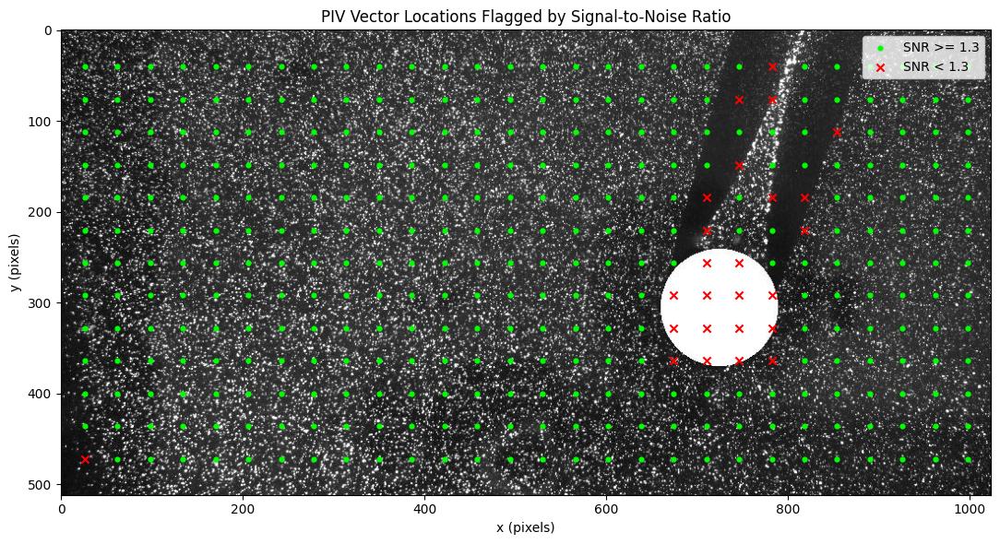

In [54]:
import matplotlib.pyplot as plt
import numpy as np

threshold = 1.3
low_snr = np.isfinite(s2n_ref) & (s2n_ref < threshold)

plt.figure(figsize=(12, 6))
plt.imshow(frame_a, cmap="gray", origin="upper")

plt.scatter(
    x24[~low_snr], y24[~low_snr],
    s=12, c="lime", label="SNR >= 1.3"
)

plt.scatter(
    x24[low_snr], y24[low_snr],
    s=35, c="red", marker="x",
    label="SNR < 1.3"
)

plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.title("PIV Vector Locations Flagged by Signal-to-Noise Ratio")
plt.legend()
plt.tight_layout()
plt.show()

Vectors inside approximate cylinder mask: 8
SNR-flagged vectors inside cylinder: 8
SNR-flagged vectors outside cylinder: 17


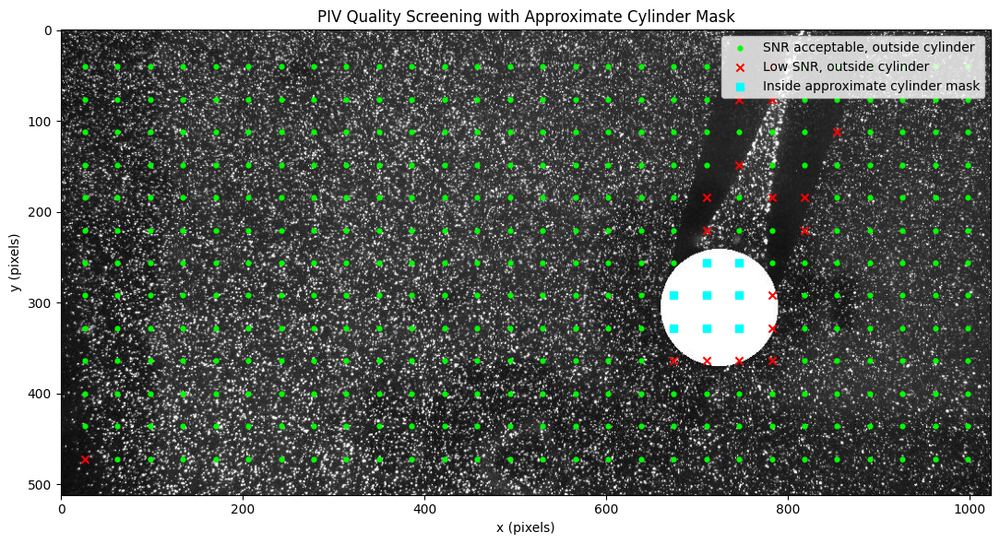

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Approximate cylinder geometry in image coordinates
cx, cy = 720, 300
radius = 60

inside_cylinder = (x24 - cx)**2 + (y24 - cy)**2 <= radius**2

print("Vectors inside approximate cylinder mask:",
      int(inside_cylinder.sum()))
print("SNR-flagged vectors inside cylinder:",
      int((low_snr & inside_cylinder).sum()))
print("SNR-flagged vectors outside cylinder:",
      int((low_snr & ~inside_cylinder).sum()))

plt.figure(figsize=(12, 6))
plt.imshow(frame_a, cmap="gray", origin="upper")
plt.scatter(x24[~low_snr & ~inside_cylinder],
            y24[~low_snr & ~inside_cylinder],
            s=12, c="lime", label="SNR acceptable, outside cylinder")
plt.scatter(x24[low_snr & ~inside_cylinder],
            y24[low_snr & ~inside_cylinder],
            s=35, c="red", marker="x", label="Low SNR, outside cylinder")
plt.scatter(x24[inside_cylinder], y24[inside_cylinder],
            s=35, c="cyan", marker="s", label="Inside approximate cylinder mask")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.title("PIV Quality Screening with Approximate Cylinder Mask")
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
fluid = ~inside_cylinder
fluid_snr_finite = fluid & np.isfinite(s2n_ref)
fluid_low_snr = fluid_snr_finite & (s2n_ref < 1.3)

print("Fluid-region vectors:", int(fluid.sum()))
print("Fluid-region vectors with finite SNR:",
      int(fluid_snr_finite.sum()))
print("Low-SNR fluid-region vectors:", int(fluid_low_snr.sum()))

n = int(fluid_snr_finite.sum())
if n:
    print("Low-SNR percentage in fluid region:",
          round(100 * fluid_low_snr.sum() / n, 2), "%")

Fluid-region vectors: 356
Fluid-region vectors with finite SNR: 356
Low-SNR fluid-region vectors: 17
Low-SNR percentage in fluid region: 4.78 %


In [57]:
import numpy as np

fluid = ~inside_cylinder
valid_vectors = (
    fluid
    & np.isfinite(u_ref)
    & np.isfinite(v_ref)
)
flagged = valid_vectors & (s2n_ref < 1.3)

print("Fluid-region vectors:", fluid.sum())
print("Finite displacement vectors:", valid_vectors.sum())
print("Low-SNR vectors:", flagged.sum())
print("Low-SNR percentage:",
      round(100 * flagged.sum() / valid_vectors.sum(), 2), "%")

Fluid-region vectors: 356
Finite displacement vectors: 356
Low-SNR vectors: 17
Low-SNR percentage: 4.78 %


In [58]:
import numpy as np
import pandas as pd
import os

# Check corrected displacement field
print("Corrected field shape:", u_clean_final.shape)
print("Finite u values:", np.isfinite(u_clean_final).sum(), "/", u_clean_final.size)
print("Finite v values:", np.isfinite(v_clean_final).sum(), "/", v_clean_final.size)

# Load the downstream profile CSV
csv_path = "/content/downstream_displacement_profile.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("\nCSV columns:", df.columns.tolist())
    print("CSV rows:", len(df))
    display(df.head(10))
else:
    print("\nCSV not found at", csv_path)
    print("Check the path where you saved the exported file.")

Corrected field shape: (13, 28)
Finite u values: 362 / 364
Finite v values: 362 / 364

CSV columns: ['x_pixels', 'mean_u_pixels_per_frame', 'std_u_pixels_per_frame']
CSV rows: 7


,x_pixels,mean_u_pixels_per_frame,std_u_pixels_per_frame
0,782.0,-1.130781,1.146794
1,818.0,-1.639918,0.277134
2,854.0,-1.832555,0.118434
3,890.0,-1.947059,0.036619
4,926.0,-1.946867,0.037223
5,962.0,-2.015515,0.046050
6,998.0,-2.038370,0.038930


In [59]:
# Check whether the CSV profile matches the current corrected field
import numpy as np
import pandas as pd

# Recompute the downstream profile using the same five rows
rows = np.arange(5, 10)
x_positions = np.array([782, 818, 854, 890, 926, 962, 998])

results = []

for x_pos in x_positions:
    col = np.argmin(np.abs(x24[0, :] - x_pos))
    values = u_clean_final[rows, col]
    values = values[np.isfinite(values)]

    results.append({
        "x_pixels": x24[0, col],
        "mean_u_pixels_per_frame": np.mean(values),
        "std_u_pixels_per_frame": np.std(values, ddof=0)
    })

recomputed = pd.DataFrame(results)
print(recomputed.round(6).to_string(index=False))

 x_pixels  mean_u_pixels_per_frame  std_u_pixels_per_frame
    782.0                -1.130781                1.025724
    818.0                -1.639918                0.247876
    854.0                -1.832555                0.105931
    890.0                -1.947059                0.032753
    926.0                -1.946867                0.033293
    962.0                -2.015515                0.041189
    998.0                -2.038370                0.034820


In [60]:
import pandas as pd
import numpy as np
from google.colab import files

rows = np.arange(5, 10)
x_positions = [782, 818, 854, 890, 926, 962, 998]

results = []

for x_pos in x_positions:
    col = np.argmin(np.abs(x24[0, :] - x_pos))
    values = u_clean_final[rows, col]
    values = values[np.isfinite(values)]

    results.append({
        "x_pixels": x24[0, col],
        "mean_u_pixels_per_frame": np.mean(values),
        "std_u_pixels_per_frame": np.std(values, ddof=0)
    })

df_updated = pd.DataFrame(results)
df_updated.to_csv("downstream_displacement_profile.csv", index=False)

display(df_updated.round(6))
files.download("downstream_displacement_profile.csv")

,x_pixels,mean_u_pixels_per_frame,std_u_pixels_per_frame
0,782.0,-1.130781,1.025724
1,818.0,-1.639918,0.247876
2,854.0,-1.832555,0.105931
3,890.0,-1.947059,0.032753
4,926.0,-1.946867,0.033293
5,962.0,-2.015515,0.041189
6,998.0,-2.038370,0.034820


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>